# Find filenames in a folder that are not present in an Excel column.

In [ ]:
import os
import pandas as pd

def find_missing_filenames(folder_path, excel_path, column_name, sheet_name=0):
    """
    Find filenames in a folder that are not present in an Excel column.
    
    Parameters:
    - folder_path: Path to the folder containing files
    - excel_path: Path to the Excel file
    - column_name: Name of the column to check against
    - sheet_name: Sheet name or index (default: 0 for first sheet)
    
    Returns:
    - List of filenames not found in Excel
    """
    
    # Get all filenames from the folder
    try:
        filenames = set(os.listdir(folder_path))
        # Filter out directories, keep only files
        filenames = {f for f in filenames if os.path.isfile(os.path.join(folder_path, f))}
        print(f"Found {len(filenames)} files in folder")
    except FileNotFoundError:
        print(f"Error: Folder not found at {folder_path}")
        return []
    
    # Read Excel file
    try:
        df = pd.read_excel(excel_path, sheet_name=sheet_name)
        print(f"Excel file loaded successfully")
    except FileNotFoundError:
        print(f"Error: Excel file not found at {excel_path}")
        return []
    except Exception as e:
        print(f"Error reading Excel: {e}")
        return []
    
    # Check if column exists
    if column_name not in df.columns:
        print(f"Error: Column '{column_name}' not found in Excel")
        print(f"Available columns: {list(df.columns)}")
        return []
    
    # Get values from the specified column (convert to set, remove NaN)
    excel_values = set(df[column_name].dropna().astype(str))
    print(f"Found {len(excel_values)} entries in column '{column_name}'")
    
    # Find filenames not in Excel
    missing_files = filenames - excel_values
    
    return sorted(list(missing_files))


# Example usage
if __name__ == "__main__":
    # Configuration
    FOLDER_PATH = "/home/fatyanosa/Projects/IndoNutriQA/data/4-anonymize_using_extracted_ner"  # Change this to your folder path
    EXCEL_PATH = "../data/5-match_qna_to_chunks/QnA.with_matches.xlsx"  # Change this to your Excel file path
    COLUMN_NAME = "File"  # Change this to your column name
    SHEET_NAME = 0  # Use sheet index (0 for first sheet) or sheet name as string
    
    # Find missing files
    missing = find_missing_filenames(FOLDER_PATH, EXCEL_PATH, COLUMN_NAME, SHEET_NAME)
    
    # Display results
    if missing:
        print(f"\n{len(missing)} file(s) not found in Excel:")
        for filename in missing:
            print(f"  - {filename}")
    else:
        print("\nAll files are present in the Excel column!")
    
    # Optional: Save missing filenames to a text file
    # if missing:
    #     output_file = "missing_files.txt"
    #     with open(output_file, 'w') as f:
    #         f.write('\n'.join(missing))
    #     print(f"\nMissing filenames saved to: {output_file}")

# Check for duplicates in the "File" column

In [ ]:
import pandas as pd

# Read the Excel file
file_path = "../data/5-match_qna_to_chunks/QnA.with_matches.xlsx"  # Replace with your file path
df = pd.read_excel(file_path)

# Check for duplicates in the "File" column
duplicates = df[df.duplicated(subset=['File'], keep=False)]

# Display results
if duplicates.empty:
    print("No duplicate values found in the 'File' column.")
else:
    print(f"Found {len(duplicates)} rows with duplicate values in the 'File' column:\n")
    print(duplicates)
    
    # Show unique duplicate values
    print("\nUnique duplicate values:")
    duplicate_values = duplicates['File'].unique()
    for value in duplicate_values:
        count = df[df['File'] == value].shape[0]
        print(f"  '{value}' appears {count} times")

# Calculate statistics

In [ ]:
import json
import numpy as np

# Load the JSON file
json_path = "../data/7-json_file_similarity/qa_pairs_with_chunks.json"

with open(json_path, 'r', encoding='utf-8') as f:
    data = json.load(f)

print(f"Total records: {len(data)}\n")

# Calculate statistics

# 1. Average Question Length (in tokens - approximated by words)
question_lengths = []
for record in data:
    question = record.get('question', '')
    # Simple tokenization: split by whitespace
    tokens = question.split()
    question_lengths.append(len(tokens))

avg_question_length = np.mean(question_lengths) if question_lengths else 0
print(f"Average Question Length: {avg_question_length:.2f} tokens")

# 2. Average Answer Length (in tokens)
answer_lengths = []
for record in data:
    answer = record.get('answer', {})
    # Handle both old format (string) and new format (dict with 'text')
    if isinstance(answer, dict) and 'text' in answer:
        answer_text = answer['text'][0] if answer['text'] else ''
    else:
        answer_text = str(answer)
    
    tokens = answer_text.split()
    answer_lengths.append(len(tokens))

avg_answer_length = np.mean(answer_lengths) if answer_lengths else 0
print(f"Average Answer Length: {avg_answer_length:.2f} tokens")

# 3. Average Context Length (in tokens)
context_lengths = []
for record in data:
    context = record.get('context', '')
    if context:
        tokens = context.split()
        context_lengths.append(len(tokens))

avg_context_length = np.mean(context_lengths) if context_lengths else 0
print(f"Average Context Length: {avg_context_length:.2f} tokens")

# 4. Unique Medical Diagnoses
unique_diagnoses = set()
for record in data:
    diagnosis = record.get('medical_diagnosis', '')
    if diagnosis:
        unique_diagnoses.add(diagnosis)

print(f"Unique Medical Diagnoses: {len(unique_diagnoses)}")

# 5. Average Chunks per Report
# Group by report_title and count chunks
report_chunks = {}
for record in data:
    report_title = record.get('file', '')
    chunk_index = record.get('chunk_index')
    
    if report_title:
        if report_title not in report_chunks:
            report_chunks[report_title] = set()
        if chunk_index is not None:
            report_chunks[report_title].add(chunk_index)

# Calculate average chunks per report
chunks_per_report = [len(chunks) for chunks in report_chunks.values()]
avg_chunks_per_report = np.mean(chunks_per_report) if chunks_per_report else 0
print(f"Average Chunks per Report: {avg_chunks_per_report:.2f}")

# Summary Table
print("\n" + "="*60)
print("DATASET STATISTICS SUMMARY")
print("="*60)
print(f"Average Question Length: {avg_question_length:.2f} tokens")
print(f"Average Answer Length: {avg_answer_length:.2f} tokens")
print(f"Average Context Length: {avg_context_length:.2f} tokens")
print(f"Unique Medical Diagnoses: {len(unique_diagnoses)}")
print(f"Average Chunks per Report: {avg_chunks_per_report:.2f}")
print(f"Total Reports: {len(report_chunks)}")
print(f"Total QA Pairs: {len(data)}")
print("="*60)

# Extract medical_diagnosis entries

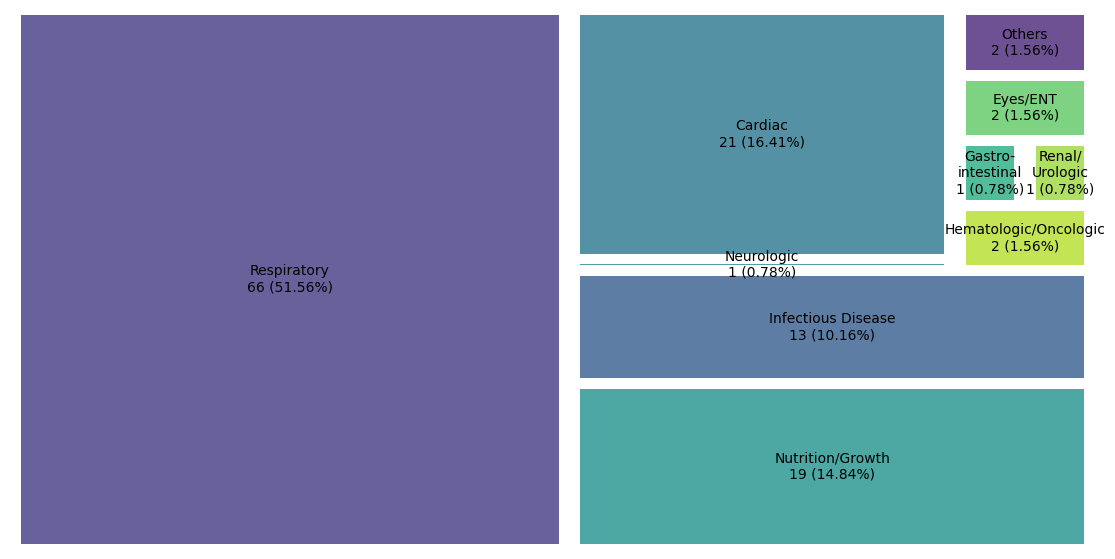

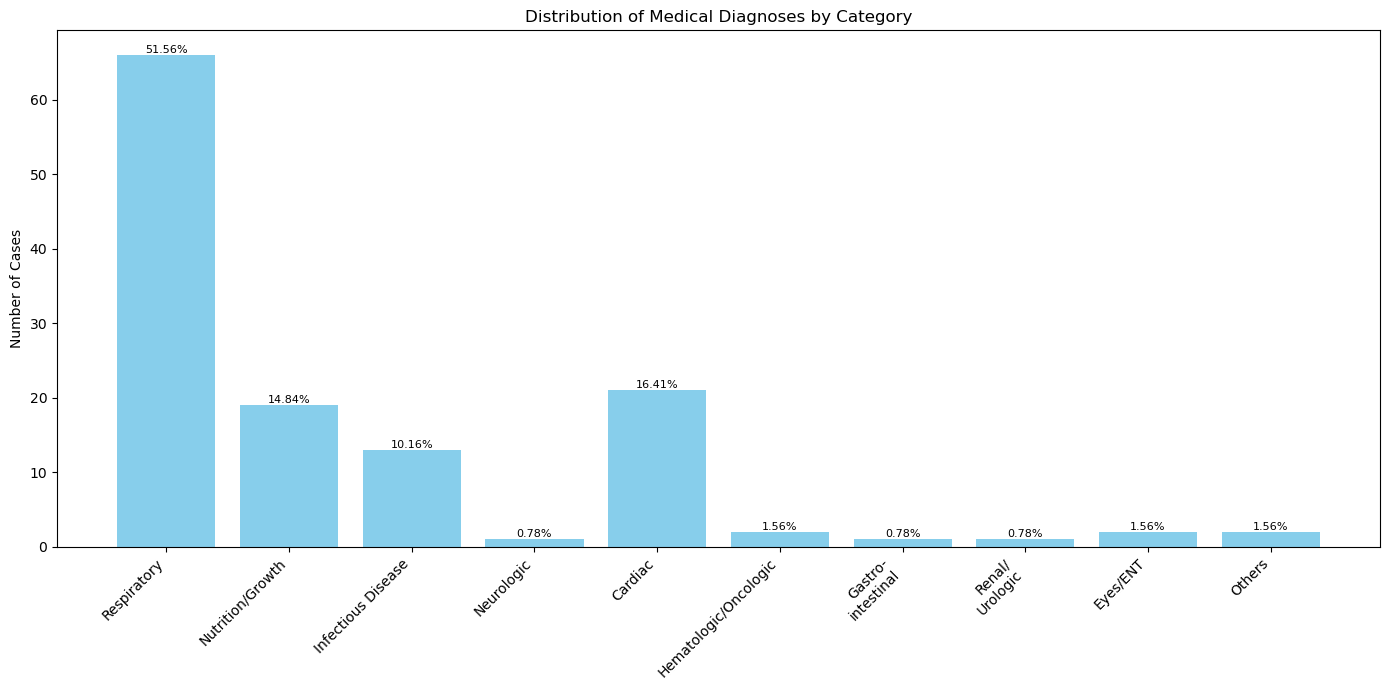

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import squarify
import re
import json

# Load data from JSON file
file_path = "../data/7-json_file_similarity/qa_pairs_with_chunks.json"
with open(file_path, 'r', encoding='utf-8') as f:
    data = json.load(f)

# Extract medical_diagnosis entries
medical_diagnosis = set()
# medical_diagnosis = [record.get('medical_diagnosis', '') for record in data if record.get('medical_diagnosis')]


for record in data:
    diagnosis = record.get('medical_diagnosis', '')
    if diagnosis:
        medical_diagnosis.add(diagnosis)

# print(f"Unique Medical Diagnoses: {len(medical_diagnosis)}")

# Expanded and comprehensive categories dictionary
categories = {
    "Respiratory": [
        "Pneumonia", "TB Paru", "ISPA", "Bronkopneumonia", "Bronchopneumoni",
        "Asma", "Asthma", "Efusi Pleura", "Abses Paru", "Batuk", "Bronkitis",
        "Respiratory Distress", "RDS", "Sesak", "Chronic Lung Disease",
        "Bronchiolitis", "Croup", "Laryngitis", "Pleuritis", "Empiema",
        "Aspirasi", "Atelektasis", "Pneumotoraks", "Hemoptisis"
    ],
    "Nutrition/Growth": [
        "Gizi Buruk", "Gizi kurang", "Gizi Kurang", "Stunting", "Stunted",
        "Malnutrisi", "Marasmus", "Kwashiorkor", "Obesitas", "Obese",
        "Wasting", "Underweight", "Failure to Thrive", "Malnutrition",
        "Overweight", "Short Stature", "Pendek", "Severe Acute Malnutrition",
        "SAM", "MAM", "Moderate Acute Malnutrition"
    ],
    "Infectious Disease": [
        "Sepsis", "Septic", "HIV", "AIDS", "DHF", "Demam Berdarah", "Dengue",
        "Typhoid", "Tifoid", "Infeksi", "Infection", "TORCH", "TBC", "Tuberculosis",
        "Hepatitis", "Meningitis", "Ensefalitis", "Encephalitis", "Malaria",
        "Campak", "Measles", "Varicella", "Cacar", "Rubella", "Mumps",
        "Polio", "Difteri", "Pertusis", "Tetanus", "Infeksi Saluran Kemih",
        "ISK", "UTI", "Urinary Tract Infection", "Bakteremia", "Viremia",
        "Cytomegalovirus", "CMV", "Herpes", "Toxoplasmosis", "Abscess"
    ],
    "Neurologic": [
        "Cerebral Palsy", "CP", "Epilepsi", "Epilepsy", "Hydrocephalus",
        "Hidrosefalus", "Seizure", "Kejang", "Ensefalopati", "Encephalopathy",
        "Retinoblastoma", "Microcephaly", "Mikrosefali", "Holoprosencephaly",
        "Development Delay", "Developmental Delay", "Global Delay", "GDD",
        "Stroke", "Cerebrovascular", "Intracranial", "Brain Injury",
        "Meningocele", "Myelomeningocele", "Spina Bifida", "Neuropati",
        "Guillain-Barre", "Ataksia", "Cerebellitis", "Tumor Otak", "Brain Tumor"
    ],
    "Cardiac": [
        "Gagal Jantung", "Heart Failure", "CHF", "PJB", "Penyakit Jantung Bawaan",
        "Congenital Heart", "ASD", "VSD", "Cardiomiopati", "Cardiomyopathy",
        "PDA", "Patent Ductus", "Ross", "Myocarditis", "Miokarditis",
        "Pulmonary Regurgitasi", "Pulmonary Regurgitation", "PR",
        "Tricuspid Regurgitasi", "Tricuspid Regurgitation", "TR",
        "TGA", "Transposition", "AR", "Aortic Regurgitation", "AS", "Aortic Stenosis",
        "TOF", "Tetralogy of Fallot", "AVSD", "Coarctation", "Endocarditis",
        "Pericarditis", "Aritmia", "Arrhythmia", "Bradikardi", "Takikardi",
        "Mitral", "Pulmonary Stenosis", "PS", "Atrial", "Ventricular"
    ],
    "Hematologic/Oncologic": [
        "Anemia", "Anemi", "Leukimia", "Leukemia", "Leukaemia", "Thrombocytopenia",
        "Trombositopenia", "Hemofilia", "Hemophilia", "Hematoma", "Hematemesis",
        "Melena", "Thalassemia", "Talasemia", "Sickle Cell", "Purpura",
        "ITP", "Idiopathic Thrombocytopenic", "Bleeding", "Perdarahan",
        "Koagulopati", "Coagulopathy", "Pansitopenia", "Neutropenia",
        "Lymphoma", "Limfoma", "Hodgkin", "Non-Hodgkin", "Leukositosis",
        "Eosinofilia", "Polisitemia", "Aplastic Anemia"
    ],
    "Gastro-\nintestinal": [
        "Diare", "Diarrhea", "Gastritis", "Gastroenteritis", "Peritonitis",
        "Colitis", "NEC", "Necrotizing Enterocolitis", "Muntah", "Vomiting",
        "Constipasi", "Konstipasi", "Sembelit", "Ulkus", "Ulcer",
        "Reflux", "GERD", "Gastroesophageal", "Intususepsi", "Intussusception",
        "Ileus", "Obstruksi Usus", "Intestinal Obstruction", "Atresia",
        "Stenosis", "Hirschsprung", "Inflammatory Bowel", "IBD", "Crohn",
        "Malrotasi", "Volvulus", "Perforasi", "Perforation", "Gastrointestinal Bleeding",
        "GI Bleeding", "Pankreatitis", "Cholecystitis", "Appendisitis"
    ],
    "Renal/\nUrologic": [
        "Acute Kidney Injury", "AKI", "Gagal Ginjal", "Kidney Failure",
        "Sindrom Nefrotik", "Nephrotic Syndrome", "CKD", "Chronic Kidney Disease",
        "CKR", "RPGN", "Glomerulonephritis", "Nefritis", "Nephritis",
        "Pyelonephritis", "Hidronefrosis", "Hydronephrosis", "Renal",
        "Uremia", "Dialisis", "Dialysis", "Hematuria", "Proteinuria",
        "Oliguria", "Anuria", "Vesicoureteral Reflux", "VUR", "Batu Ginjal",
        "Urolithiasis", "Phimosis", "Paraphimosis", "Hypospadias"
    ],
    "Endocrine/Metabolic": [
        "DM", "Diabetes", "Diabetes Mellitus", "Hipoglikemi", "Hypoglycemia",
        "Hipokalsemia", "Hypocalcemia", "Hiponatremia", "Hyponatremia",
        "Hipernatremia", "Hypernatremia", "Hipokalemia", "Hypokalemia",
        "Hiperkalemia", "Hyperkalemia", "Metabolik", "Metabolic", "Acidosis",
        "Alkalosis", "Inborn Error", "IEM", "Hipotiroid", "Hypothyroid",
        "Hipertiroid", "Hyperthyroid", "Thyroid", "Adrenal", "Cushing",
        "Growth Hormone", "GH", "Rickets", "Vitamin D", "Osteoporosis",
        "Hyperglycemia", "Ketoacidosis", "DKA"
    ],
    "Oncology/Tumor": [
        "Tumor", "Kanker", "Cancer", "Neurofibromatosis", "Histiositosis",
        "Histiocytosis", "Retinoblastoma", "Lymphoma", "Sarcoma", "Neuroblastoma",
        "Wilms", "Glioma", "Medulloblastoma", "Hepatoblastoma", "Rhabdomyosarcoma",
        "Osteosarcoma", "Ewing", "Langerhans", "LCH", "Leukemia", "Mass",
        "Massa", "Neoplasm", "Malignancy", "Ganas"
    ],
    "Perinatal/Neonatal": [
        "Prematur", "Preterm", "Premature", "BBLR", "Low Birth Weight", "LBW",
        "Asfiksia", "Asphyxia", "Birth Asphyxia", "Hiperbilirubin", "Hyperbilirubinemia",
        "Ikterus", "Jaundice", "Neonatus", "Neonatal", "Newborn", "Late Preterm",
        "VLBW", "Very Low Birth Weight", "ELBW", "Extremely Low Birth Weight",
        "SGA", "Small for Gestational Age", "LGA", "Large for Gestational Age",
        "AGA", "TTN", "Transient Tachypnea", "Meconium", "Sepsis Neonatorum",
        "Respiratory Distress Syndrome", "HIE", "Hypoxic Ischemic", "Kernicterus"
    ],
    "Musculoskeletal": [
        "Arthritis", "Artritis", "Osteomielitis", "Osteomyelitis", "Fraktur",
        "Fracture", "Patah Tulang", "Myopati", "Myopathy", "Distrofi",
        "Muscular Dystrophy", "Skoliosis", "Scoliosis", "Kifosis", "Kyphosis",
        "Lordosis", "Clubfoot", "CTEV", "Talipes", "Dislokasi", "Dislocation",
        "Hip Dysplasia", "DDH", "Osteogenesis Imperfecta", "Rickets",
        "Juvenil Idiopatik Artritis", "JIA", "Septic Arthritis"
    ],
    "Dermatologic": [
        "Dermatitis", "Skabies", "Scabies", "Impetigo", "Ektima", "Ecthyma",
        "Moluscum", "Molluscum Contagiosum", "Krustosa", "Eksim", "Eczema",
        "Atopic Dermatitis", "Psoriasis", "Vitiligo", "Alopecia", "Selulitis",
        "Cellulitis", "Abses Kulit", "Skin Abscess", "Erythema", "Rash",
        "Ruam", "Urtikaria", "Urticaria", "Angioedema", "Stevens-Johnson",
        "SJS", "TEN", "Toxic Epidermal Necrolysis"
    ],
    "Hepatic/Biliary": [
        "Sirosis", "Cirrhosis", "Hepatitis", "Cholangitis", "Hepatoma",
        "Hepatocellular Carcinoma", "Liver Injury", "Liver Failure",
        "Gagal Hati", "Cholestasis", "Kolestasis", "Atresia Bilier",
        "Biliary Atresia", "Cholelithiasis", "Batu Empedu", "Fatty Liver",
        "Steatosis", "Hepatosplenomegaly", "Hepatomegali", "Liver Disease",
        "Penyakit Hati", "Cholecystitis", "Ascites", "Asites"
    ],
    "Surgical/Congenital Anomalies": [
        "Hernia", "Laparotomi", "Laparotomy", "Appendicitis", "Apendisitis",
        "PSARP", "Posterior Sagittal Anorectoplasty", "Explorasi", "Exploration",
        "Obstruksi", "Obstruction", "Invaginasi", "Intussusception",
        "Fistula", "Atresia", "Stenosis", "Malformasi", "Malformation",
        "Anorektal", "Anorectal", "Imperforate Anus", "Anus Imperforata",
        "Gastroschisis", "Omphalocele", "Omfalokel", "Diafragmatik Hernia",
        "CDH", "Cleft", "Labioschisis", "Palatoschisis", "Labiopalatoschisis",
        "Cleft Lip", "Cleft Palate", "OEIS Complex", "Ekstrofia", "Exstrophy",
        "Hirschsprung", "Tracheoesophageal Fistula", "TEF"
    ],
    "Immunologic/Allergic": [
        "Alergi", "Allergy", "Asma", "Asthma", "Urtikaria", "Angioedema",
        "Anaphylaxis", "Anafilaksis", "Imunodefisiensi", "Immunodeficiency",
        "SCID", "Severe Combined Immunodeficiency", "Autoimmune", "Autoimun",
        "Lupus", "SLE", "Systemic Lupus", "Rheumatoid", "Vaskulitis",
        "Vasculitis", "Kawasaki", "Henoch-Schonlein", "HSP"
    ],
    "Eyes/ENT": [
        "Konjungtivitis", "Conjunctivitis", "Katarak", "Cataract",
        "Glaukoma", "Glaucoma", "Retinopati", "Retinopathy", "Otitis",
        "Otitis Media", "OM", "Sinusitis", "Faringitis", "Pharyngitis",
        "Tonsilitis", "Tonsillitis", "Laringitis", "Laryngitis",
        "Rhinitis", "Rinitis", "Epistaksis", "Epistaxis", "Nose Bleed",
        "Mastoiditis", "Hearing Loss", "Gangguan Pendengaran", "Tuli"
    ],
    "Poisoning/Toxicology": [
        "Keracunan", "Poisoning", "Intoxication", "Overdose", "Toxic",
        "Toksik", "Envenomation", "Snake Bite", "Gigitan Ular",
        "Drug Reaction", "Reaksi Obat", "Heavy Metal"
    ],
    "Others": []  # catch-all
}

# Assign categories
category_counts = {cat: 0 for cat in categories}
for diag in medical_diagnosis:
    assigned = False
    for cat, keywords in categories.items():
        for kw in keywords:
            if kw.lower() in diag.lower():
                category_counts[cat] += 1
                assigned = True
                break
        if assigned:
            break
    if not assigned:
        category_counts["Others"] += 1

# Convert to DataFrame
df = pd.DataFrame(list(category_counts.items()), columns=["Category", "Count"])
df = df[df["Count"] > 0]

# Add percentages
total = df["Count"].sum()
df["Percentage"] = (df["Count"] / total * 100).round(2)

# print(df)

# --- Treemap ---
plt.figure(figsize=(14, 7))
labels = [f"{cat}\n{count} ({pct}%)" for cat, count, pct in zip(df["Category"], df["Count"], df["Percentage"])]
squarify.plot(sizes=df["Count"], label=labels, alpha=0.8, pad=True, text_kwargs={'fontsize': 10})
# plt.title("Medical Diagnoses by Category", fontsize=25)
plt.axis('off')
plt.savefig("diagnosisdistribution.pdf", format="pdf", bbox_inches="tight")
plt.show()

# --- Bar Chart ---
plt.figure(figsize=(14, 7))
plt.fontsize = 12
bars = plt.bar(df["Category"], df["Count"], color="skyblue")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of Cases")
plt.title("Distribution of Medical Diagnoses by Category")

# Add percentage labels
for bar, pct in zip(bars, df["Percentage"]):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f"{pct}%", ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()



In [2]:
import pandas as pd

# Load the Excel file
file_path = "Antropometri dan Diagnosis Medis.xlsx"
df = pd.read_excel(file_path)

print(df.columns)

# Extract non-null diagnosis entries
raw_cases = df["Assessment Antropometri"].dropna().astype(str).tolist()


import re

cleaned_data = []

for case in raw_cases:
    entry = {}
    text = str(case)

    # Sex
    if "laki" in text.lower():
        entry["Sex"] = "Male"
    elif "perempuan" in text.lower():
        entry["Sex"] = "Female"
    else:
        entry["Sex"] = None

    # Age
    age_match = re.search(
    r"(Usia|Umur)\s*[:=]?\s*((\d+)\s*tahun)?\s*((\d+)\s*bulan)?\s*((\d+)\s*hari)?",
    text, re.IGNORECASE
    )

    if age_match:
        years = int(age_match.group(3)) if age_match.group(3) else 0
        months = int(age_match.group(5)) if age_match.group(5) else 0
        days = int(age_match.group(7)) if age_match.group(7) else 0
        entry["Age_months"] = years * 12 + months + round(days / 30, 2)
    else:
        entry["Age_months"] = None

    # Weight
    weight_match = re.search(r"\bBB(?:L| aktual)?\s*[:=]?\s*([\d,\.]+)", text, re.IGNORECASE)

    if weight_match:
        val = float(weight_match.group(1).replace(",", "."))
        entry["Weight_kg"] = val / 1000 if val > 1000 else val

    else:
        # Fallback: capture BBI in different sentence structures
        bbi_match = re.search(
            r"\bBBI(?:\/U)?(?:\s*(?:menurut|berdasarkan)\s*[A-Za-z\s]*)?(?:[:=]|adalah)?\s*([\d,\.]+)",
            text,
            re.IGNORECASE
        )
        if bbi_match:
            val = float(bbi_match.group(1).replace(",", "."))
            entry["Weight_kg"] = val / 1000 if val > 1000 else val
        else:
            entry["Weight_kg"] = None

    # Height / Length (TB / PB)
    height_match = re.search(r"\b(TB|PB)\s*[:=]?\s*([\d,\.]+)", text, re.IGNORECASE)
    entry["Height_cm"] = float(height_match.group(2).replace(",", ".")) if height_match else None

    # MUAC (LILA/LLA)
    muac_match = re.search(r"(LILA|LLA)\s*[:=]?\s*([\d,\.]+)", text, re.IGNORECASE)
    entry["MUAC_cm"] = float(muac_match.group(2).replace(",", ".")) if muac_match else None

    # Head Circumference (LK)
    hc_match = re.search(r"(LK|Lingkar Kepala)\s*[:=]?\s*([\d,\.]+)", text, re.IGNORECASE)
    entry["HeadCirc_cm"] = float(hc_match.group(2).replace(",", ".")) if hc_match else None

    # BMI (IMT)
    bmi_match = re.search(r"IMT\s*[:=]?\s*([\d,\.]+)", text, re.IGNORECASE)
    entry["BMI"] = float(bmi_match.group(1).replace(",", ".")) if bmi_match else None

    cleaned_data.append(entry)

clean_df = pd.DataFrame(cleaned_data)

clean_df.to_csv("Antropometri_cleaned.csv", index=False, encoding="utf-8-sig")


Index(['Assessment Antropometri', 'Diagnosis Medis'], dtype='object')


In [3]:
len(df)

128

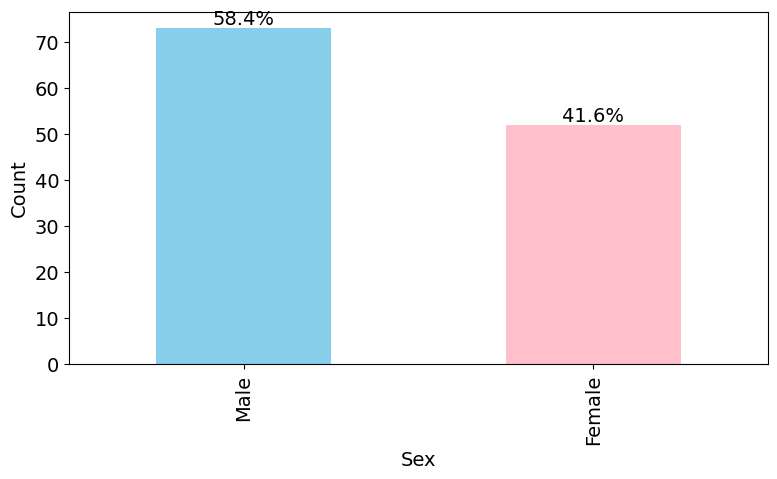

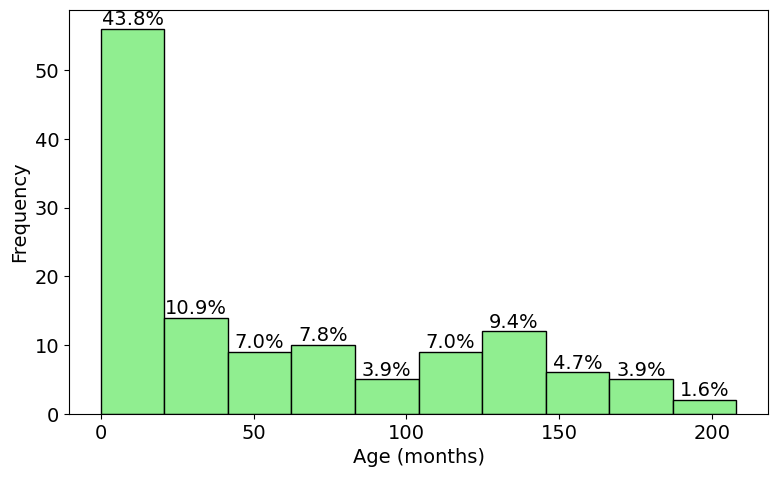

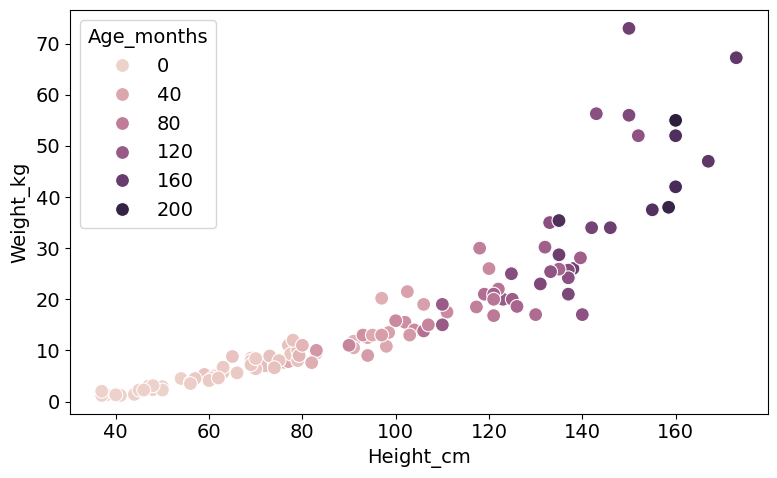

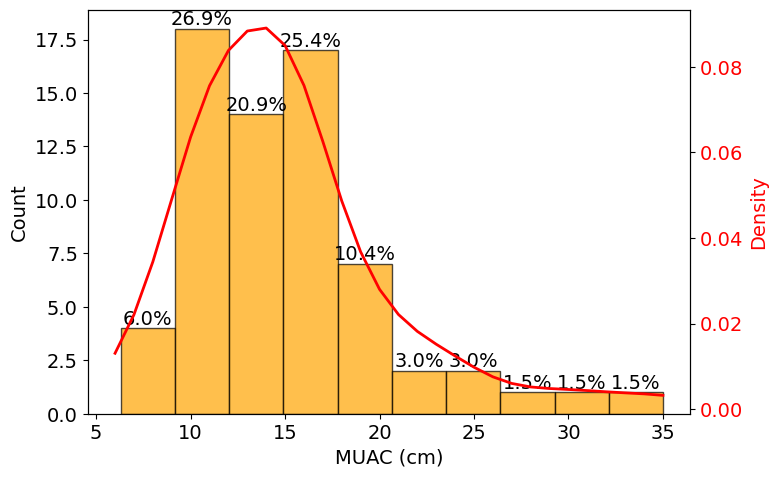

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams.update({'font.size': 14})

fig, ax = plt.subplots(figsize=(8, 5))

# 1. Sex distribution
sex_counts = clean_df["Sex"].value_counts()
total_sex = sex_counts.sum()
ax = sex_counts.plot(kind="bar", color=["skyblue", "pink"])
# plt.title("Sex Distribution")
plt.xlabel("Sex")
plt.ylabel("Count")


# Add percentage labels on bars
for i, v in enumerate(sex_counts):
    percentage = (v / total_sex) * 100
    ax.text(i, v, f'{percentage:.1f}%', ha='center', va='bottom')

plt.tight_layout()
plt.savefig("sex.pdf", format="pdf", bbox_inches="tight")
plt.show()

# 2. Age distribution
fig, ax = plt.subplots(figsize=(8, 5))
n, bins, patches = ax.hist(clean_df["Age_months"], bins=10, color="lightgreen", edgecolor="black")
# plt.title("Age Distribution (months)")
plt.xlabel("Age (months)")
plt.ylabel("Frequency")

# Add percentage labels on histogram bars
total_age = sum(n)
for i, (patch, count) in enumerate(zip(patches, n)):
    if count > 0:  # Only show label if count is not zero
        height = patch.get_height()
        percentage = (count / total_age) * 100
        ax.text(patch.get_x() + patch.get_width()/2, height,
                f'{percentage:.1f}%', ha='center', va='bottom')

plt.tight_layout()
plt.savefig("age.pdf", format="pdf", bbox_inches="tight")
plt.show()

# 3. Weight vs Height scatter with annotations
fig, ax = plt.subplots(figsize=(8, 5))
scatter = sns.scatterplot(data=clean_df, x="Height_cm", y="Weight_kg", hue="Age_months", s=100, ax=ax)
# plt.title("Weight vs Height by Age")

# Add point count annotation with percentage
total_records = len(clean_df)
total_points = clean_df[['Height_cm', 'Weight_kg']].dropna().shape[0]
percentage_plotted = (total_points / total_records) * 100 if total_records > 0 else 0

# stats_text = f'Total points: {total_points}\n({percentage_plotted:.1f}% of records)'
# plt.text(0.02, 0.98, stats_text, 
#          transform=ax.transAxes, fontsize=10, verticalalignment='top',
#          bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.savefig("weight_height.pdf", format="pdf", bbox_inches="tight")
plt.show()

# 4. MUAC distribution

fig, ax = plt.subplots(figsize=(8, 5))

muac_data = clean_df["MUAC_cm"].dropna()



# Create histogram and get bin information
counts, bins_edges, patches = ax.hist(muac_data, bins=10, color="orange", edgecolor="black", alpha=0.7)

# Add KDE line
from scipy import stats
if len(muac_data) > 1:
    density = stats.gaussian_kde(muac_data)
    xs = range(int(muac_data.min()), int(muac_data.max()) + 1)
    ax2 = ax.twinx()
    ax2.plot(xs, density(xs), color='red', linewidth=2)
    ax2.set_ylabel('Density', color='red')
    ax2.tick_params(axis='y', labelcolor='red')

# plt.title("MUAC (LILA) Distribution")
ax.set_xlabel("MUAC (cm)")
ax.set_ylabel("Count")



# Add percentage labels on histogram bars
total_muac = sum(counts)
for i, (patch, count) in enumerate(zip(patches, counts)):
    if count > 0:
        height = patch.get_height()
        percentage = (count / total_muac) * 100
        ax.text(patch.get_x() + patch.get_width()/2, height,
                f'{percentage:.1f}%', ha='center', va='bottom')

# Add statistics annotation
mean_muac = muac_data.mean()
median_muac = muac_data.median()
count_muac = len(muac_data)
total_records = len(clean_df)
percentage_available = (count_muac / total_records) * 100 if total_records > 0 else 0

# stats_text = f'Count: {count_muac} ({percentage_available:.1f}%)\nMean: {mean_muac:.2f} cm\nMedian: {median_muac:.2f} cm'
# ax.text(0.98, 0.98, stats_text, transform=ax.transAxes, 
#          fontsize=10, verticalalignment='top', horizontalalignment='right',
#          bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.savefig("lila.pdf", format="pdf", bbox_inches="tight")
plt.show()

# # 5. Nutritional Status frequency (if you have this column)
# if "Nutritional_Status" in clean_df.columns:
#     status_counts = clean_df["Nutritional_Status"].value_counts()
#     total_status = status_counts.sum()
#     ax = status_counts.plot(kind="bar", color="purple")
#     plt.title("Nutritional Status Categories")
#     plt.xlabel("Category")
#     plt.ylabel("Count")
#     
#     # Add percentage labels on bars
#     for i, v in enumerate(status_counts):
#         percentage = (v / total_status) * 100
#         ax.text(i, v, f'{percentage:.1f}%', ha='center', va='bottom', fontweight='bold')
#     
#     plt.tight_layout()
#     plt.show()